### **Setup (only for this file)**
These lines repeat what Parts 1 and 2 already do: the setup, the functions of Part 2, the 12 temporal splits and the candidates of 21.1. They are generated from the code of Part 2, so the two files can not drift apart, and they are removed when Part 3 is joined to the main notebook.

In [1]:
import pandas as pd
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

train_path=os.path.join("..","data","raw","train.csv")
clientes_path=os.path.join("..","data","raw","clientes.csv")

df_train= pd.read_csv(train_path,index_col="ID",sep=",")
df_clientes = pd.read_csv(clientes_path, sep=",")

target_col = "repeat_purchase_90d"
var_groups = {
    "Current transaction (financial)": ["Total a Pagar", "Total Bruto", "Total Liquido", "Total Imp_", "Total Portes",
                                        "Total Desc_ Global", "Total Desc_ Linha", "Custo"],
    "Current transaction (operational)": ["N_ Detalhes", "invoice_count_current_purchase"],
    "Customer historical summary": ["customer_tenure_days", "prior_purchase_count", "prior_total_spend",
                                    "prior_mean_purchase_value", "prior_std_purchase_value",
                                    "prior_min_purchase_value", "prior_max_purchase_value"],
    "Customer cadence & gaps": ["days_since_previous_purchase", "prior_mean_gap_days", "prior_std_gap_days"],
    "Rolling windows (RFM)": ["purchase_count_30d", "spend_30d", "purchase_count_90d", "spend_90d",
                              "purchase_count_180d", "spend_180d", "purchase_count_365d", "spend_365d"],
}

# recover_values of 3.6.7
def recover_values(frame):
    """Fills the cells that can be computed exactly from other columns of the same row (3.6.1 and 3.6.7)."""
    out = frame.copy()
    count, tenure = out["prior_purchase_count"], out["customer_tenure_days"]
    out["prior_mean_purchase_value"] = out["prior_total_spend"] / count.replace(0, np.nan)

    days, gap = out["days_since_previous_purchase"].copy(), out["prior_mean_gap_days"].copy()
    fill = days.isna() & (count == 1)
    out.loc[fill, "days_since_previous_purchase"] = tenure[fill]
    fill = days.isna() & (count >= 2) & gap.notna()
    out.loc[fill, "days_since_previous_purchase"] = (tenure - gap * (count - 1))[fill]
    fill = gap.isna() & (count >= 2) & days.notna()
    out.loc[fill, "prior_mean_gap_days"] = ((tenure - days) / (count - 1))[fill]

    fill = out["spend_365d"].isna() & (out["purchase_count_365d"] == 0)
    out.loc[fill, "spend_365d"] = 0.0
    fill = out["spend_365d"].isna() & (out["purchase_count_365d"] == out["purchase_count_180d"])
    out.loc[fill, "spend_365d"] = out.loc[fill, "spend_180d"]
    fill = out["spend_365d"].isna() & (out["purchase_count_365d"] == count)
    out.loc[fill, "spend_365d"] = out.loc[fill, "prior_total_spend"]

    fill = out["prior_max_purchase_value"].isna() & (count == 1)
    out.loc[fill, "prior_max_purchase_value"] = out.loc[fill, "prior_total_spend"]
    fill = out["prior_max_purchase_value"].isna() & (count == 2)
    out.loc[fill, "prior_max_purchase_value"] = (out["prior_total_spend"] - out["prior_min_purchase_value"])[fill]
    return out

In [2]:
import warnings
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (OneHotEncoder, OrdinalEncoder, FunctionTransformer,
                                   StandardScaler, MinMaxScaler, RobustScaler)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, f1_score
from sklearn.exceptions import ConvergenceWarning

# without scaling the solver can stop at its limit of iterations. We look at this in section 18, so we hide the warning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

In [3]:
def signed_log(X):
    """log1p that keeps the sign. For values >= 0 it is the same as log1p, and it also works
    on the negative impossible values of the option "keep as is" (13.4)."""
    return np.sign(X) * np.log1p(np.abs(X))


class Winsorizer(BaseEstimator, TransformerMixin):
    """Clips each column to its 1% and 99% quantiles, learned on the train rows."""
    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        self.low_ = np.nanquantile(X, 0.01, axis=0)
        self.high_ = np.nanquantile(X, 0.99, axis=0)
        return self

    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.low_, self.high_)


def make_preprocessor(log_cols, plain_cols, cat_cols, flag_cols=(), num_fill="median", indicators=False,
                      cat_fill="Missing", outliers="log1p", encoder="onehot", min_frequency=None, scaler="standard"):
    """Layer B: the steps that learn something from the data (medians, levels, scales).
    Inside a Pipeline they are fitted only on the train rows of each split."""
    scalers = {"standard": StandardScaler, "minmax": MinMaxScaler, "robust": RobustScaler}

    def numeric_steps(long_tail):
        if num_fill == "zero":
            steps = [("impute", SimpleImputer(strategy="constant", fill_value=0, add_indicator=indicators))]
        else:
            steps = [("impute", SimpleImputer(strategy=num_fill, add_indicator=indicators))]
        if long_tail and outliers == "log1p":
            steps.append(("log", FunctionTransformer(signed_log)))
        elif long_tail and outliers == "winsorize":
            steps.append(("winsorize", Winsorizer()))
        if scaler in scalers:
            steps.append(("scale", scalers[scaler]()))
        return Pipeline(steps)

    # categories: missing -> "Missing" (or the most frequent level), then encoding
    if cat_fill == "Missing":
        cat_steps = [("impute", SimpleImputer(strategy="constant", fill_value="Missing"))]
    else:
        cat_steps = [("impute", SimpleImputer(strategy="most_frequent"))]
    if encoder == "onehot" and min_frequency is None:
        cat_steps.append(("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False)))
    elif encoder == "onehot":
        cat_steps.append(("encode", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=min_frequency,
                                                  sparse_output=False)))
    else:
        cat_steps.append(("encode", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)))
        if scaler in scalers:
            cat_steps.append(("scale", scalers[scaler]()))

    parts = [("log", numeric_steps(long_tail=True), list(log_cols)),       # money, counts and days (long tails)
             ("plain", numeric_steps(long_tail=False), list(plain_cols)),  # columns that can be negative, or ratios
             ("cat", Pipeline(cat_steps), list(cat_cols)),
             ("flags", "passthrough", list(flag_cols))]                    # 0/1 columns
    return ColumnTransformer([p for p in parts if len(p[2]) > 0])


def temporal_scores(frame, columns, recipe, row_filter=None, metric="ap"):
    """One score per fold: the instrument is fitted on the train rows and scored on the validation block."""
    used = columns["log_cols"] + columns["plain_cols"] + columns["cat_cols"] + columns["flag_cols"]
    scores = []
    for train_idx, val_idx in folds:
        train, val = frame.loc[train_idx], frame.loc[val_idx]
        if row_filter is not None:
            train = row_filter(train)   # rows are only removed from the train side, never from validation
        pipe = Pipeline([("prep", make_preprocessor(**columns, **recipe)),
                         ("model", LogisticRegression(max_iter=3000))])
        pipe.fit(train[used], train[target_col])
        prob = pipe.predict_proba(val[used])[:, 1]
        if metric == "ap":
            scores.append(average_precision_score(val[target_col], prob))
        elif metric == "f1":
            scores.append(f1_score(val[target_col], prob >= 0.5))
        else:
            scores.append((prob >= 0.5).mean())   # share of rows predicted as 1
    return np.array(scores)


def compare(results, reference):
    """Mean AP of each option and its difference to the reference, fold by fold (paired)."""
    rows = {}
    for name, scores in results.items():
        diff = scores - results[reference]
        sem = diff.std(ddof=1) / np.sqrt(len(diff))
        if name == reference:
            verdict = "reference"
        elif abs(diff.mean()) <= 2 * sem:
            verdict = "inside the noise"
        else:
            verdict = "better" if diff.mean() > 0 else "worse"
        rows[name] = {"AP": round(scores.mean(), 4), "difference": round(diff.mean(), 4), "SEM": round(sem, 4),
                      "better in": f"{(diff > 0).sum()}/{len(diff)}", "verdict": verdict}
    return pd.DataFrame(rows).T


def blank_impossible(frame):
    """Impossible values of 3.6 -> missing. It works row by row, so it learns nothing from the other rows."""
    out = frame.copy()
    count = out["prior_purchase_count"]
    # 3.6.1 to 3.6.3: 1e9, negative values, means bigger than the biggest purchase, spend_365d bigger than the prior spend
    mean = out["prior_mean_purchase_value"]
    out.loc[(mean < 0) | (mean >= 1e8) | (mean > out["prior_max_purchase_value"] + 0.01), "prior_mean_purchase_value"] = np.nan
    spend = out["spend_365d"]
    out.loc[(spend < 0) | (spend >= 1e8) | (spend > out["prior_total_spend"] + 0.01), "spend_365d"] = np.nan
    for col in ["days_since_previous_purchase", "prior_mean_gap_days"]:
        out.loc[out[col] < 0, col] = np.nan
    # 3.6.6: biggest purchase above its limit
    max_limit = out["prior_total_spend"] - (count - 1) * out["prior_min_purchase_value"]
    out.loc[(count >= 1) & (out["prior_max_purchase_value"] > max_limit + 0.01), "prior_max_purchase_value"] = np.nan
    return out


def add_features(frame):
    """New variables, built row by row from the columns of the same purchase."""
    out = frame.copy()
    months = out["customer_tenure_days"] / 30
    out["bought_in_90d"] = (out["purchase_count_90d"] > 0).astype(int)
    out["rhythm_ratio"] = out["days_since_previous_purchase"] / out["prior_mean_gap_days"].replace(0, np.nan)
    out["purchase_rate"] = out["prior_purchase_count"] / (months + 1)
    out["spend_per_month"] = out["prior_total_spend"] / (months + 1)
    out["avg_basket_365d"] = out["spend_365d"] / out["purchase_count_365d"].replace(0, np.nan)
    out["spend_acceleration"] = out["spend_30d"] / (out["spend_90d"] + 1)
    out["margin_ratio"] = (out["Total Liquido"] - out["Custo"]) / (out["Total Liquido"] + 1)
    out["discount_intensity"] = (out["Total Desc_ Linha"] + out["Total Desc_ Global"]) / (out["Total Bruto"] + 1)
    out["value_vs_habit"] = ((out["Total a Pagar"] - out["prior_mean_purchase_value"])
                             / out["prior_std_purchase_value"].replace(0, np.nan))
    return out


def prepare_data(frame, clientes):
    """Layer A: every step that works row by row. The same function will be used on test.csv."""
    out = frame.copy()
    out["purchase_date"] = pd.to_datetime(out["purchase_date"])
    out = blank_impossible(out)
    out = recover_values(out)          # 3.6.7
    out["is_first_purchase"] = (out["prior_purchase_count"] == 0).astype(int)
    out = out.join(clientes.set_index("customer_id")[["country_or_region", "commercial_region", "island",
                                                      "municipality", "postal_area"]],
                   on="customer_id", validate="many_to_one")
    out["incomplete_address"] = (out["municipality"].isna() & out["postal_area"].isna()).astype(int)
    out = add_features(out)
    return out

In [4]:
# 12.1 and 12.2: rows without the empty ones, development rows and the 12 temporal splits
empty_rows = df_train.drop(columns=["customer_id", target_col]).isna().all(axis=1)
df_model = prepare_data(df_train.loc[~empty_rows], df_clientes)
is_dev = df_model["purchase_date"] < "2024-01-01"
dev = df_model.loc[is_dev]
block_starts = pd.date_range("2018-01-01", "2023-07-01", freq="6MS")
folds = []
for start in block_starts:
    end = start + pd.DateOffset(months=6)
    train_idx = dev.index[dev["purchase_date"] < start - pd.Timedelta(days=90)]
    val_idx = dev.index[(dev["purchase_date"] >= start) & (dev["purchase_date"] < end)]
    folds.append((train_idx, val_idx))

# 21.1: the candidates and the recipe that Part 2 hands to Part 3
final_columns = {
    "log_cols": [
        "Total a Pagar", "Total Bruto", "Total Liquido", "Total Imp_", "Total Portes",
        "Total Desc_ Global", "Total Desc_ Linha", "Custo", "N_ Detalhes",
        "invoice_count_current_purchase", "customer_tenure_days", "prior_purchase_count",
        "prior_total_spend", "prior_mean_purchase_value", "prior_std_purchase_value",
        "prior_min_purchase_value", "prior_max_purchase_value", "days_since_previous_purchase",
        "prior_mean_gap_days", "prior_std_gap_days", "purchase_count_30d", "spend_30d",
        "purchase_count_90d", "spend_90d", "purchase_count_180d", "spend_180d", "purchase_count_365d",
        "spend_365d", "rhythm_ratio", "purchase_rate", "spend_per_month", "avg_basket_365d"],
    "plain_cols": [
        "random_noise", "spend_acceleration", "margin_ratio", "discount_intensity", "value_vs_habit"],
    "cat_cols": [
        "payment_type", "salesperson", "commercial_zone", "transport_method", "warehouse",
        "document_series", "country_or_region", "commercial_region", "island"],
    "flag_cols": [
        "is_first_purchase", "incomplete_address"],
}
final_recipe = {"num_fill": "median", "indicators": False, "cat_fill": "Missing", "outliers": "log1p", "encoder": "onehot", "min_frequency": 10, "scaler": "standard"}
feature_cols = final_columns["log_cols"] + final_columns["plain_cols"] + final_columns["cat_cols"] + final_columns["flag_cols"]
print(f"Rows: {len(df_model):,} | Development: {is_dev.sum():,} | Candidates: {len(feature_cols)}")

Rows: 6,469 | Development: 5,634 | Candidates: 48


### **22. Feature Selection: How We Select**

In Part 2 we built the candidates: 48 variables (21.1), with `random_noise` among them. Not all of them are useful. Some are almost copies of others (section 8), some have almost no relation with the target, and one is pure noise. A model with fewer variables is easier to explain and has fewer chances to learn noise, so in Part 3 we decide which variables stay.

The guidelines ask for a clear strategy with the methods of the classes, so we use the three families of the classes, first each one alone:
* **filter methods** (section 24): each variable is judged alone, with statistics;
* a **wrapper method** (section 25): RFE, which judges the variables through a model;
* **embedded methods** (section 26): the L1 penalty and the importance of a random forest, which select while the model is fitted.

Before that, section 23 looks at the identifier-like variables, as the guidelines ask. At the end we combine the methods (27) and present the final set (28).

Two rules hold in all of Part 3:
* **Every method only looks at the train rows of each split.** Choosing variables uses the target, so it is a step that learns from the data, like Layer B. If we chose them with all the rows, the validation blocks would help to choose the variables that they then evaluate.
* **A variable only stays if it beats a control.** Each method gives a score or a ranking, and then we need a cut: how many variables stay. In the classes the cut was a fixed number (C = 0.1 for L1, the median for the tree), or the best point on the validation blocks (the k of RFE). The classes also say that this best point is too optimistic, because the same blocks choose the cut and measure it. Here we use controls, columns that we know have no information: a variable only stays if the method finds it stronger than its control. For the numeric variables the control is `random_noise`, as planned in the EDA (section 10). So no cut is chosen by looking at the AP.

In [5]:
import sklearn
from scipy.stats import spearmanr, chi2_contingency
from sklearn.feature_selection import RFE, VarianceThreshold
from sklearn.ensemble import RandomForestClassifier

# scikit-learn 1.8 changed how the lasso penalty is written: l1_ratio=1, as in the class notebook.
# Older versions only know penalty="l1", so we use the spelling of the installed version.
if tuple(int(v) for v in sklearn.__version__.split(".")[:2]) >= (1, 8):
    LASSO = {"l1_ratio": 1}
else:
    LASSO = {"penalty": "l1"}

#### **22.1. The Starting Point and the Controls**

We start from the end of Part 2: `df_model`, the 48 candidates and the recipe (Layer B). In each split Layer B is fitted on the train rows only once, and the matrices are kept, so all the methods read exactly the same columns. The unit of the selection is the **variable**, not the column: a category is kept or removed with all its one-hot columns. The final set is a list of variables that goes into `make_preprocessor`, and the recipe of Part 2 keeps deciding how each category is encoded.

`random_noise` is a fair control for a numeric variable, because both are one column. A category is different: it has one column for each level, so it has many chances to look useful by luck, and section 25 shows that `random_noise` is a control that is too easy for it. So each category and each flag gets its own control: a **shuffled copy** of itself. Its rows are mixed, so it has the same levels and the same number of columns, but no relation with the target. A category only stays if it beats its own shuffled copy.

The shuffled copies are added to the train matrix of each split, and every column is scaled (25 explains why). This selection matrix is only read by RFE, L1 and the random forest: the instrument never sees the copies.

In [6]:
def encoded_names(prep):
    """Names of the columns that Layer B creates, in the order of the matrix."""
    names = []
    for name, steps, cols in prep.transformers_:
        if name == "cat":
            names += list(steps.named_steps["encode"].get_feature_names_out(cols))
        elif name != "remainder":
            names += list(cols)
    return np.array(names)


def variable_of(names):
    """The variable behind each encoded column: a dummy belongs to its categorical variable."""
    return np.array([next((c for c in final_columns["cat_cols"] if n.startswith(c + "_")), n) for n in names])


# the control of each variable: random_noise for the numeric variables, a shuffled copy of itself for the categories and flags
shuffled_vars = final_columns["cat_cols"] + final_columns["flag_cols"]
control = {v: f"shuffled {v}" if v in shuffled_vars else "random_noise" for v in feature_cols}


def selection_matrix(X_train, variable, rng):
    """The train matrix plus the shuffled copies (rows mixed: same levels and columns, no relation with the target),
    with every column scaled. RFE, L1 and the random forest read this matrix; the instrument never sees the copies."""
    copies = [X_train[rng.permutation(len(X_train))][:, variable == v] for v in shuffled_vars]
    names = [f"shuffled {v}" for v in shuffled_vars for _ in range((variable == v).sum())]
    return StandardScaler().fit_transform(np.hstack([X_train] + copies)), np.concatenate([variable, names])


# Layer B fitted on the train rows of each split, only once, so every method below reads the same matrices
rng = np.random.default_rng(44)
splits = []
for train_idx, val_idx in folds:
    prep = make_preprocessor(**final_columns, **final_recipe)
    X_train = prep.fit_transform(df_model.loc[train_idx, feature_cols])
    names = encoded_names(prep)
    X_select, select_variable = selection_matrix(X_train, variable_of(names), rng)
    splits.append({"train_idx": train_idx, "names": names, "variable": variable_of(names),
                   "X_train": X_train, "y_train": df_model.loc[train_idx, target_col].to_numpy(),
                   "X_val": prep.transform(df_model.loc[val_idx, feature_cols]),
                   "y_val": df_model.loc[val_idx, target_col].to_numpy(),
                   "X_select": X_select, "select_variable": select_variable})

print(f"Candidate variables: {len(feature_cols)} | Encoded columns per split: {[len(s['names']) for s in splits]}")
print(f"Columns with the shuffled copies (fold 12): {splits[-1]['X_select'].shape[1]}")

Candidate variables: 48 | Encoded columns per split: [99, 104, 108, 112, 114, 116, 121, 122, 126, 132, 135, 135]
Columns with the shuffled copies (fold 12): 233


The number of columns grows with the train rows, from 99 in fold 1 to 135 in fold 12: with more rows, more levels reach the 10 rows that give them their own column (section 17). With the shuffled copies, the selection matrix of fold 12 has 233 columns.

#### **22.2. How a Selection Is Measured**

To measure a selection we use the instrument of Part 2: in each split the logistic regression is fitted on the train rows with only the variables kept in that split, and it scores the validation block. So each selection gets 12 APs, and `compare` puts it next to all the candidates (paired, with the SEM, as in Part 2). Next to the AP we show three more numbers:
* **variables kept**: the mean of the 12 splits;
* **random_noise kept**: in how many splits the selection keeps the noise (a good selection never keeps it);
* **stability**: how similar the sets of the different splits are. For two splits it is the Jaccard similarity (variables in both sets / variables in at least one of them), and we show the mean of all the pairs of splits: 1 means the same set in every split. A selection that changes a lot from split to split depends on the rows it saw, so it tells us little about the variables.

In [27]:
def selection_ap(kept_sets):
    """AP of the instrument in each split, with only the variables kept in that split."""
    scores = []
    for split, kept in zip(splits, kept_sets):
        cols = np.isin(split["variable"], list(kept))
        if not cols.any():   # no variable left: the model knows nothing, so its AP is the repeat rate
            scores.append(average_precision_score(split["y_val"], np.zeros(len(split["y_val"]))))
            continue
        model = LogisticRegression(max_iter=3000).fit(split["X_train"][:, cols], split["y_train"])
        scores.append(average_precision_score(split["y_val"], model.predict_proba(split["X_val"][:, cols])[:, 1]))
    return np.array(scores)


def stability(kept_sets):
    """Mean Jaccard similarity between the sets of two splits: 1 means the same set in every split."""
    pairs = [(a, b) for i, a in enumerate(kept_sets) for b in kept_sets[i + 1:]]
    return np.mean([len(a & b) / len(a | b) for a, b in pairs])


board, kept_by = {}, {}


def measure(name, kept_sets):
    """Scores a selection (one set of variables per split) and keeps it for the tables."""
    board[name], kept_by[name] = selection_ap(kept_sets), kept_sets


def show(names):
    """The selections side by side, against all the candidates."""
    table = compare({n: board[n] for n in ["all candidates"] + names}, "all candidates")
    table["variables kept"] = [round(np.mean([len(s) for s in kept_by[n]]), 1) for n in table.index]
    table["random_noise kept"] = [f"{sum('random_noise' in s for s in kept_by[n])}/12" for n in table.index]
    table["stability"] = [round(stability(kept_by[n]), 2) for n in table.index]
    return table


measure("all candidates", [set(feature_cols)] * len(splits))
print(f"AP with all the candidates: {board['all candidates'].mean():.4f}")

AP with all the candidates: 0.8346


All the 48 candidates give an AP of 0.835, the same as the final recipe of Part 2 (21.2). This is the reference of every table of Part 3. In Part 2 the instrument was robust to almost every choice, so the question here is not if a selection beats this AP, but if it can keep it with fewer variables.

### **23. Identifier-like Variables**

The guidelines ask to treat the identifier-like variables critically, not to accept them automatically. In the EDA (section 10) we left `ID` and `customer_id` out by principle: `ID` is the number of the row, and the small correlation of `customer_id` with the target (−0.12) comes from a few very active clients. In Part 2 we also removed the columns of `clientes.csv` that work like identifiers (section 19), and we grouped the rare levels of the categories (section 17).

Lets now test this with the instrument. We add `ID` as a number, and `customer_id` as a number (its code) and as a category (one column for each client with 10 or more train rows, the rule of section 17). This is the most favourable case for an identifier, because the validation blocks are full of clients that the model already saw.

In [8]:
# ID as a number, and customer_id as a number (its code) and as a category (one column per client with 10 or more train rows)
df_ids = df_model.assign(row_id=df_model.index.astype(float),
                         customer_number=df_model["customer_id"].astype(float),
                         customer_level=df_model["customer_id"].astype(str))
results = {
    "all candidates": board["all candidates"],
    "+ ID as a number": temporal_scores(
        df_ids, {**final_columns, "plain_cols": final_columns["plain_cols"] + ["row_id"]}, final_recipe),
    "+ customer_id as a number": temporal_scores(
        df_ids, {**final_columns, "plain_cols": final_columns["plain_cols"] + ["customer_number"]}, final_recipe),
    "+ customer_id as a category": temporal_scores(
        df_ids, {**final_columns, "cat_cols": final_columns["cat_cols"] + ["customer_level"]}, final_recipe),
}
seen = [df_model.loc[val_idx, "customer_id"].isin(df_model.loc[train_idx, "customer_id"]).mean() for train_idx, val_idx in folds]
print(f"Validation purchases made by clients that are already in the train rows: {min(seen):.0%} to {max(seen):.0%}")
compare(results, "all candidates")

Validation purchases made by clients that are already in the train rows: 80% to 94%


,AP,difference,SEM,better in,verdict
all candidates,0.8346,0.0,0.0,0/12,reference
+ ID as a number,0.8341,-0.0005,0.0005,6/12,inside the noise
+ customer_id as a number,0.8349,0.0003,0.0004,8/12,inside the noise
+ customer_id as a category,0.8238,-0.0108,0.0056,5/12,inside the noise


Neither identifier helps. `ID` and `customer_id` as numbers are inside the noise, with differences close to 0: a row number and a client code say nothing that the other variables do not already say. `customer_id` as a category loses about 0.011 of AP, at the limit of the noise (about 2 SEM), even though 80% to 94% of the validation purchases come from clients that the model already saw. A column for each client only knows the past of that client, while the history variables are updated at every purchase and also work for new clients.

So the identifiers stay out, as decided in the EDA. But a category can also work like an identifier when its levels belong to few clients, so lets check the categories that are candidates.

In [9]:
# do the categories still identify clients? Levels as Layer B sees them in the biggest train set (fold 12)
train_12 = df_model.loc[folds[-1][0]]
rows = []
for col in final_columns["cat_cols"]:
    level = train_12[col].fillna("Missing")
    counts = level.value_counts()
    own = counts[counts >= final_recipe["min_frequency"]].index        # levels with their own column
    clients = train_12.groupby(level)["customer_id"].nunique()
    rows.append({"variable": col, "levels": len(counts), "levels with own column": len(own),
                 "of these, used by 1 client": int((clients[own] == 1).sum()),
                 "used by fewer than 5 clients": int((clients[own] < 5).sum()),
                 "same value in all purchases of a client": f"{(train_12.groupby('customer_id')[col].nunique(dropna=False) <= 1).mean():.0%}"})
pd.DataFrame(rows).set_index("variable")

,levels,levels with own column,"of these, used by 1 client",used by fewer than 5 clients,same value in all purchases of a client
variable,,,,,
payment_type,8,6,0,0,76%
salesperson,10,8,0,0,70%
commercial_zone,5,3,0,0,99%
transport_method,76,35,1,7,49%
warehouse,3,3,0,0,80%
document_series,3,3,0,0,47%
country_or_region,7,2,0,0,100%
commercial_region,32,19,0,2,100%
island,11,10,0,0,100%


In the biggest train set (fold 12), after the grouping of section 17, only 1 level of `transport_method` still belongs to a single client (a client with many purchases, since a level needs 10 train rows to get its own column), and only a few levels are used by fewer than 5 clients (7 in `transport_method` and 2 in `commercial_region`). So the levels describe groups of clients, not single clients.

The last column shows something else: the geography (`country_or_region`, `commercial_region` and `island`) is the same in all the purchases of a client, and `commercial_zone` almost (99%). These variables describe the client, not the purchase. This is not a problem by itself, but a region with only a few clients works a bit like a client ID. This is one more reason for the controls of 22.1: a category only stays if it beats a shuffled copy of itself, with the same levels.

### **24. Filter Methods**

The filter methods judge each variable alone, without a model, with the statistics of the EDA. As in the classes there are three steps: the columns that never change (24.1), the relevance, which is the relation of each variable with the target (24.2), and the redundancy, which is the relation between two variables (24.3). Then we put them together in one filter (24.4).

#### **24.1. Constant Columns**

In [10]:
# VarianceThreshold(0) removes the columns that never change in the train rows
constant = [int(len(s["names"]) - VarianceThreshold(0).fit(s["X_train"]).get_support().sum()) for s in splits]
print(f"Constant columns in each split: {constant}")

Constant columns in each split: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


No column is constant in any split, so `VarianceThreshold` has nothing to remove. As in the classes, it only finds constant columns and it can not rank the others: a 0/1 column and a scaled column have variances that can not be compared.

#### **24.2. Relevance**

For the relevance we use the statistic of each type, as in the EDA: the Spearman correlation for the numeric variables and the flags (7.1), and the chi-square test with the Cramér's V for the categories (7.5), on the levels as Layer B sees them (rare levels grouped). Both go from 0 to 1, so all the variables can be ranked together. Each test also gives a p-value: when it is below 0.05, the relation is unlikely to come from chance. Everything is computed on the train rows of each split, so we show the mean relevance of the 12 splits and in how many splits the test is significant.

In [11]:
numeric_vars = final_columns["log_cols"] + final_columns["plain_cols"] + final_columns["flag_cols"]
cat_vars = final_columns["cat_cols"]


def levels_seen(split, col):
    """The level of each train row as Layer B sees it (rare levels grouped)."""
    cols = np.flatnonzero(split["variable"] == col)
    return pd.Series(split["names"][cols][split["X_train"][:, cols].argmax(axis=1)])


def cramers_v(a, b):
    """Cramer's V and the p-value of the chi-square test between two categorical columns."""
    table = pd.crosstab(a, b)
    if min(table.shape) < 2:          # only one level in these rows: no association to measure
        return 0.0, 1.0
    chi2, p, _, _ = chi2_contingency(table, correction=False)
    return np.sqrt(chi2 / (table.to_numpy().sum() * (min(table.shape) - 1))), p


def association(split):
    """Relevance of each variable with the target in the train rows, and the p-value of its test:
    Spearman for numeric variables and flags (7.1), chi-square and Cramer's V for categories (7.5)."""
    rows = df_model.loc[split["train_idx"]]
    out = {}
    for col in numeric_vars:
        known = rows[col].notna()
        rho, p = spearmanr(rows.loc[known, col], rows.loc[known, target_col])
        out[col] = {"relevance": abs(rho), "p-value": p}
    for col in cat_vars:
        v, p = cramers_v(levels_seen(split, col), pd.Series(split["y_train"]))
        out[col] = {"relevance": v, "p-value": p}
    return pd.DataFrame(out).T


assoc = [association(s) for s in splits]
relevance = pd.DataFrame({i: a["relevance"] for i, a in enumerate(assoc)})
significant = pd.DataFrame({i: a["p-value"] < 0.05 for i, a in enumerate(assoc)})
relevance_table = pd.DataFrame({"relevance (mean of 12 splits)": relevance.mean(axis=1).round(3),
                                "significant (p < 0.05) in": significant.sum(axis=1).astype(str) + "/12"})
print(f"Relevance of purchase_count_365d | fold 1: {relevance.loc['purchase_count_365d', 0]:.2f}"
      f" | fold 12: {relevance.loc['purchase_count_365d', len(splits) - 1]:.2f}")
relevance_table.sort_values("relevance (mean of 12 splits)", ascending=False)

Relevance of purchase_count_365d | fold 1: 0.31 | fold 12: 0.42


,relevance (mean of 12 splits),significant (p < 0.05) in
purchase_rate,0.391,12/12
purchase_count_365d,0.386,12/12
purchase_count_90d,0.381,12/12
prior_mean_gap_days,0.376,12/12
purchase_count_180d,0.373,12/12
spend_365d,0.370,12/12
spend_per_month,0.367,12/12
spend_90d,0.365,12/12
spend_180d,0.363,12/12
prior_total_spend,0.317,12/12


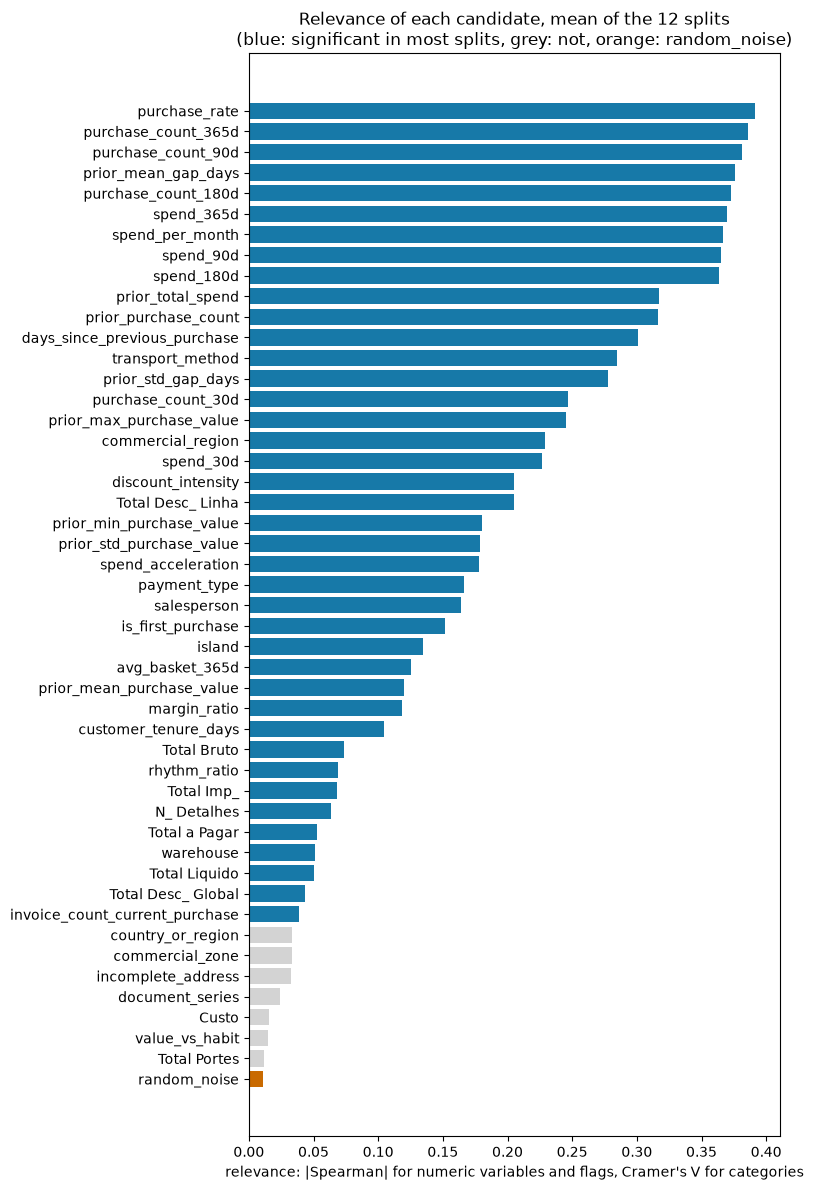

In [12]:
order = relevance.mean(axis=1).sort_values().index
colors = ["#C96A00" if v == "random_noise" else "#1779A8" if significant.loc[v].sum() > 6 else "lightgrey" for v in order]
fig, ax = plt.subplots(figsize=(8, 12))
ax.barh(order, relevance.mean(axis=1)[order], color=colors)
ax.set_xlabel("relevance: |Spearman| for numeric variables and flags, Cramer's V for categories")
ax.set_title("Relevance of each candidate, mean of the 12 splits\n(blue: significant in most splits, grey: not, orange: random_noise)")
plt.tight_layout()
plt.show()

The ranking is the one of the EDA: frequency and recency are at the top (`purchase_rate`, `purchase_count_365d`, `purchase_count_90d`, `prior_mean_gap_days`), significant in every split. The values are lower than in the EDA (0.44 for `purchase_count_365d` in 7.2) because they are a mean of the 12 train sets, and the first ones are small and have a big share of 2015, where the history is incomplete (section 14). The relation of `purchase_count_365d` goes from 0.31 in fold 1 to 0.42 in fold 12.

At the bottom, `random_noise` is the last one and is never significant, which is what a good test should say. Three variables are not better than the noise: `value_vs_habit` (as we saw in section 20), `Custo` and `Total Portes`, also never significant. `document_series` is significant in only 2 splits (in the EDA its V was close to 0), and `country_or_region`, `commercial_zone` and `incomplete_address` in only 4.

#### **24.3. Redundancy**

Two variables can both be relevant and still say the same thing. As in the EDA (section 8), we use the Spearman correlation between the numeric variables and look at the pairs above 0.90. For the categories we use the Cramér's V between each pair. Again, only the train rows of each split are used.

In [13]:
def redundancy(split):
    """|Spearman| between the numeric variables and Cramer's V between the categories, in the train rows."""
    rows = df_model.loc[split["train_idx"]]
    numeric = rows[numeric_vars].corr(method="spearman").abs()
    levels = {col: levels_seen(split, col) for col in cat_vars}
    categorical = pd.DataFrame({a: {b: cramers_v(levels[a], levels[b])[0] for b in cat_vars} for a in cat_vars})
    return numeric, categorical


redund = [redundancy(s) for s in splits]

# the pairs above 0.90 in the biggest train set (fold 12)
numeric_12, categorical_12 = redund[-1]
pairs = [(a, b, numeric_12.loc[a, b]) for i, a in enumerate(numeric_vars) for b in numeric_vars[i + 1:]
         if numeric_12.loc[a, b] > 0.90]
print(f"Pairs of numeric variables above 0.90: {len(pairs)}")
v_pairs = categorical_12.where(~np.eye(len(cat_vars), dtype=bool)).stack()
print(f"Highest Cramer's V between two different categories: {v_pairs.max():.2f} ({' and '.join(v_pairs.idxmax())})")
pd.DataFrame(pairs, columns=["variable", "same information as", "|Spearman|"]).sort_values("|Spearman|", ascending=False).round(3).set_index("variable")

Pairs of numeric variables above 0.90: 15
Highest Cramer's V between two different categories: 0.78 (country_or_region and commercial_region)


,same information as,|Spearman|
variable,,
Total a Pagar,Total Liquido,1.000
Total Bruto,Total Liquido,0.992
Total a Pagar,Total Bruto,0.991
spend_30d,spend_acceleration,0.967
purchase_count_30d,spend_30d,0.964
purchase_count_30d,spend_acceleration,0.939
prior_std_purchase_value,prior_max_purchase_value,0.935
prior_mean_gap_days,purchase_rate,0.934
prior_mean_purchase_value,avg_basket_365d,0.924


In the biggest train set 15 pairs are above 0.90. Most of them are the pairs of the EDA (section 8), plus `Total a Pagar` with `Total Imp_`, just above 0.90 here. The others involve the new features of section 20, which are close to the columns they are built from (`spend_acceleration` with `spend_30d`, `purchase_rate` with `prior_mean_gap_days`, `spend_per_month` with `spend_365d`...). Between the categories the highest V is 0.78, for `country_or_region` and `commercial_region` (the country and the region of the client). No pair of categories is above 0.90, so the redundancy rule only removes numeric variables.

#### **24.4. The Filter**

The filter puts relevance and redundancy together, as in the classes. The variables are walked from the most relevant to the least relevant, and a variable stays if its test is significant (p < 0.05) and if it does not repeat (above 0.90) a variable that already stayed. So from each group of redundant variables, the most relevant one stays.

We compare this filter with three other versions: only the test, a stricter limit for the redundancy (0.70), and only the 10 most relevant variables (a fixed budget, like the `SelectKBest` of the classes).

In [14]:
def filter_variables(a, numeric, categorical, threshold=0.90, alpha=0.05, budget=None):
    """Walks the variables from the most relevant to the least relevant. A variable stays if its test is
    significant and if it does not repeat (above threshold) a variable that already stayed.
    Returns the variables that stay and the reason why each other variable leaves."""
    kept, reason = [], {}
    for col in a["relevance"].sort_values(ascending=False).index:
        if a.loc[col, "p-value"] >= alpha:
            reason[col] = "not significant"
            continue
        if budget is not None and len(kept) == budget:
            reason[col] = "outside the budget"
            continue
        if threshold is not None:
            matrix = numeric if col in numeric_vars else categorical
            repeats = [k for k in kept if k in matrix.index and matrix.loc[col, k] > threshold]
            if repeats:
                reason[col] = "repeats " + repeats[0]
                continue
        kept.append(col)
    return set(kept), reason


filters = {
    "test only": dict(threshold=None),
    "test + redundancy 0.90": dict(threshold=0.90),
    "test + redundancy 0.70": dict(threshold=0.70),
    "test + 10 most relevant": dict(threshold=None, budget=10),
}
for name, settings in filters.items():
    measure("filter: " + name, [filter_variables(assoc[i], *redund[i], **settings)[0] for i in range(len(splits))])
show(["filter: " + name for name in filters])

,AP,difference,SEM,better in,verdict,variables kept,random_noise kept,stability
all candidates,0.8346,0.0,0.0,0/12,reference,48.0,12/12,1.00
filter: test only,0.8366,0.002,0.002,5/12,inside the noise,39.2,0/12,0.88
filter: test + redundancy 0.90,0.8377,0.0031,0.0021,7/12,inside the noise,27.2,0/12,0.71
filter: test + redundancy 0.70,0.8345,-0.0001,0.0022,5/12,inside the noise,18.6,0/12,0.56
filter: test + 10 most relevant,0.8304,-0.0042,0.0041,4/12,inside the noise,10.0,0/12,0.89


All four versions are inside the noise, and none of them keeps `random_noise`. The test alone removes about 9 variables. The redundancy limit of 0.90 removes about 12 more and has the best AP on average (+0.003). Going further costs AP: with a limit of 0.70, or with only the 10 most relevant variables, the instrument loses what it gained. The 10 most relevant are the lowest on average, because they are all frequency, recency and spend variables (24.2): a fixed budget keeps many copies of the same information and nothing else.

So the filter of the next sections is the test plus the redundancy limit of 0.90, the same limit we used in the EDA (section 8). It keeps about 27 variables. Its stability (0.71) is lower than the one of the test alone, because the variable that stays in a redundant group is the most relevant one of each split, and in some groups the most relevant one changes from split to split.

### **25. Wrapper Method: Recursive Feature Elimination**

A wrapper judges the variables through a model, so it can see what a filter can not: a variable that is weak alone but useful together with others, or a relevant variable that adds nothing because another one already says the same. As in the classes we use RFE with the logistic regression: it fits the model, removes the column with the smallest coefficient, and repeats until only one column is left. The order in which the variables leave is a ranking, from the weakest to the strongest (a category leaves when its last column leaves).

RFE compares the size of the coefficients, so all the columns must be on the same scale. The instrument scales the numeric columns but leaves the 0/1 columns as they are (section 18): the column of a rare level then needs a big coefficient to change the probability of its few rows, and RFE would read this as importance. This is why RFE reads the selection matrix of 22.1, where every column is scaled. The controls are ranked together with the candidates, so lets first see where they fall.

In [15]:
def rfe_ranking(split, allowed=None):
    """RFE on the selection matrix, one column per step as in the classes. A variable leaves when its last
    column leaves. Returns the variables and the controls, from the strongest to the weakest."""
    cols = np.isin(split["select_variable"], list(allowed)) if allowed is not None else np.ones(len(split["select_variable"]), bool)
    # liblinear: the same logistic regression, faster for the many fits of RFE
    rfe = RFE(LogisticRegression(solver="liblinear", max_iter=3000), n_features_to_select=1, step=1)
    rfe.fit(split["X_select"][:, cols], split["y_train"])
    best_rank = pd.Series(rfe.ranking_, index=split["select_variable"][cols]).groupby(level=0).min()
    return list(best_rank.sort_values().index)


rankings = [rfe_ranking(s) for s in splits]

# where do the controls fall? Place among the 48 candidates and the 11 shuffled copies
controls = ["random_noise"] + [f"shuffled {v}" for v in shuffled_vars]
places = pd.DataFrame({i: {c: r.index(c) + 1 for c in controls} for i, r in enumerate(rankings)})
pd.DataFrame({"place (mean of 12 splits)": places.mean(axis=1).round(1),
              "best place": places.min(axis=1),
              "above random_noise in": ["–"] + [f"{(places.loc[c] < places.loc['random_noise']).sum()}/12" for c in controls[1:]]})

,place (mean of 12 splits),best place,above random_noise in
random_noise,45.7,36,–
shuffled payment_type,33.4,12,11/12
shuffled salesperson,24.7,13,11/12
shuffled commercial_zone,37.6,18,8/12
shuffled transport_method,28.0,17,11/12
shuffled warehouse,38.6,25,7/12
shuffled document_series,43.9,25,6/12
shuffled country_or_region,35.1,22,10/12
shuffled commercial_region,27.0,17,11/12
shuffled island,29.5,21,12/12


`random_noise` is near the end of the ranking (around place 46). But most shuffled categories are above it: the shuffled copies of `island`, `salesperson`, `transport_method`, `commercial_region` and `payment_type` beat `random_noise` in almost every split. These copies have no information at all, so this is luck: a category has many columns, and with many columns one of them always looks useful. The shuffled flags have one column, like `random_noise`, and they fall close to it.

So `random_noise` would be a control that is too easy for a category. RFE keeps a variable only when it is ranked above **its own** control: `random_noise` for a numeric variable, its shuffled copy for a category or a flag.

In [16]:
def above_control(ranking, candidates=feature_cols):
    """The candidates ranked above their own control."""
    return {v for v in candidates if v in ranking and ranking.index(v) < ranking.index(control[v])}


measure("RFE: above its control", [above_control(r) for r in rankings])
show(["RFE: above its control"])

,AP,difference,SEM,better in,verdict,variables kept,random_noise kept,stability
all candidates,0.8346,0.0,0.0,0/12,reference,48.0,12/12,1.00
RFE: above its control,0.8349,0.0002,0.0008,7/12,inside the noise,35.3,0/12,0.69


RFE keeps about 35 variables and gives the same AP as all the candidates, without `random_noise`. It removes the variables that are clearly weak, but it keeps most of the redundant ones: when two columns say the same thing the model splits the coefficient between them, and both can stay above their control. The filter does the opposite and keeps only one variable of each group.

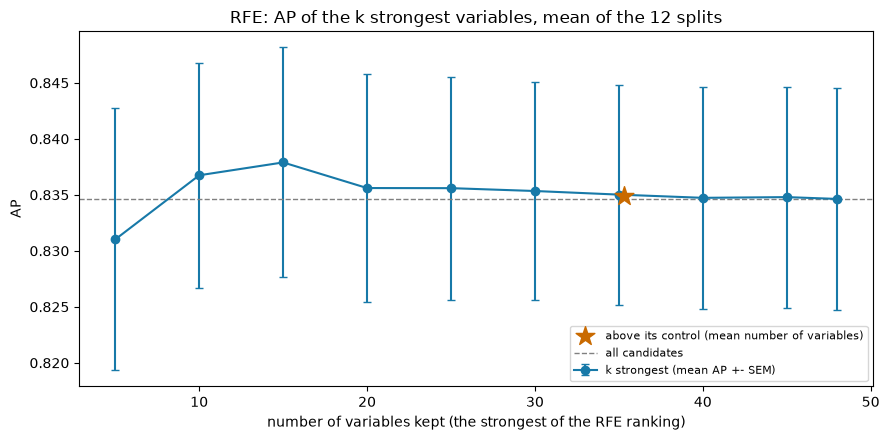

,5,10,15,20,25,30,35,40,45,48
AP,0.8310,0.8367,0.8379,0.8356,0.8356,0.8353,0.8350,0.8347,0.8348,0.8346
SEM,0.0117,0.0100,0.0103,0.0101,0.0099,0.0097,0.0098,0.0099,0.0099,0.0099


In [17]:
# the class way: the k strongest variables of each split, for several k (the controls are not counted)
real_rankings = [[v for v in r if v in feature_cols] for r in rankings]
widths_k = [5, 10, 15, 20, 25, 30, 35, 40, 45, len(feature_cols)]
curve = {k: selection_ap([set(r[:k]) for r in real_rankings]) for k in widths_k}
curve = pd.DataFrame({"AP": [c.mean() for c in curve.values()],
                      "SEM": [c.std(ddof=1) / np.sqrt(len(c)) for c in curve.values()]}, index=widths_k)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.errorbar(curve.index, curve["AP"], yerr=curve["SEM"], marker="o", capsize=3, color="#1779A8", label="k strongest (mean AP +- SEM)")
ax.scatter(np.mean([len(s) for s in kept_by["RFE: above its control"]]), board["RFE: above its control"].mean(),
           marker="*", s=200, color="#C96A00", zorder=5, label="above its control (mean number of variables)")
ax.axhline(board["all candidates"].mean(), color="grey", linestyle="--", linewidth=1, label="all candidates")
ax.set(xlabel="number of variables kept (the strongest of the RFE ranking)", ylabel="AP",
       title="RFE: AP of the k strongest variables, mean of the 12 splits")
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()
curve.round(4).T

This is the curve of the classes, with the k strongest variables of each split. With 5 variables the AP is lower, it is highest around 10 to 15 variables, and from 20 variables on it slowly goes down to the AP of all the candidates. All these differences are small (the error bars overlap). In the classes k is the point with the best AP, but this AP is too optimistic: the same validation blocks choose k and measure it (the selection bias of the slides). Our cut does not look at the AP (orange star). It keeps more variables than the best point of the curve, because RFE alone does not remove the redundant variables.

### **26. Embedded Methods**

The embedded methods select while the model is fitted. We use the two of the classes: the L1 penalty of the logistic regression (26.1) and the importance of a tree model (26.2), here a random forest, which is more stable than a single tree.

#### **26.1. L1 Penalty (Lasso)**

The L1 penalty (lasso) pushes the coefficients of the weak columns to exactly 0, and C sets how strong it is: the smaller C, the stronger the penalty and the more columns at 0. The classes used C = 0.1. Lets follow the path of the penalty from strong to weak, on the selection matrix (every column scaled, for the same reason as RFE), and see when the controls enter.

In [18]:
C_grid = [0.001, 0.002, 0.005, 0.01, 0.02, 0.05, 0.1, 0.2, 0.5, 1.0]


def lasso_path(split, allowed=None):
    """For each C, from the strongest penalty to the weakest: the variables and controls with at least one column
    that the L1 penalty does not set to 0."""
    cols = np.isin(split["select_variable"], list(allowed)) if allowed is not None else np.ones(len(split["select_variable"]), bool)
    path = {}
    for C in C_grid:
        model = LogisticRegression(solver="liblinear", C=C, max_iter=3000, random_state=44, **LASSO)
        model.fit(split["X_select"][:, cols], split["y_train"])
        alive = pd.Series(np.abs(model.coef_[0]) > 1e-8, index=split["select_variable"][cols]).groupby(level=0).any()
        path[C] = set(alive[alive].index)
    return path


paths = [lasso_path(s) for s in splits]
pd.DataFrame({C: {"variables kept (mean)": round(np.mean([len(p[C] & set(feature_cols)) for p in paths]), 1),
                  "random_noise kept": f"{sum('random_noise' in p[C] for p in paths)}/12",
                  "shuffled copies kept (mean)": round(np.mean([len(p[C] - set(feature_cols)) for p in paths]), 1),
                  "AP": round(selection_ap([p[C] & set(feature_cols) for p in paths]).mean(), 4)}
              for C in C_grid}).T.rename_axis("C")

,variables kept (mean),random_noise kept,shuffled copies kept (mean),AP
C,,,,
0.001,0.1,0/12,0.0,0.5658
0.002,1.4,0/12,0.0,0.7154
0.005,4.5,0/12,0.0,0.8257
0.010,8.6,0/12,0.1,0.8341
0.020,14.7,0/12,1.9,0.8345
0.050,20.8,6/12,7.5,0.8336
0.100,27.5,10/12,9.7,0.8341
0.200,32.0,11/12,10.2,0.8352
0.500,35.8,11/12,10.8,0.8348


With a strong penalty almost nothing stays, and the AP falls (with C = 0.001 the model is almost empty and its AP is close to the repeat rate). As C grows more variables enter, and from C = 0.01 on the AP is already close to the one of all the candidates. The controls show the problem of a fixed C: with the C of the classes (0.1), `random_noise` is kept in 10 of 12 splits and almost all the shuffled copies are kept too. At this C the penalty is too weak to remove pure noise. The shuffled copies also enter earlier than `random_noise`, for the same reason as in RFE: many columns, many chances.

So, as for RFE, each variable is compared with its own control: L1 keeps a variable when it enters the path (from the strongest penalty to the weakest) before its control.

In [19]:
def before_control(path, candidates=feature_cols):
    """The candidates that enter the path (from the strongest penalty to the weakest) before their own control."""
    first = {}
    for C in C_grid:
        for v in path[C]:
            first.setdefault(v, C)
    return {v for v in candidates if first.get(v, np.inf) < first.get(control[v], np.inf)}


measure("L1: before its control", [before_control(p) for p in paths])
measure("L1: C = 0.1 (class value)", [p[0.1] & set(feature_cols) for p in paths])
show(["L1: before its control", "L1: C = 0.1 (class value)"])

,AP,difference,SEM,better in,verdict,variables kept,random_noise kept,stability
all candidates,0.8346,0.0,0.0,0/12,reference,48.0,12/12,1.00
L1: before its control,0.8352,0.0006,0.0016,7/12,inside the noise,19.3,0/12,0.60
L1: C = 0.1 (class value),0.8341,-0.0006,0.0008,6/12,inside the noise,27.5,10/12,0.76


L1 keeps about 19 variables, inside the noise of all the candidates, and never `random_noise`. The C of the classes gives a similar AP with about 27 variables, but with the noise in 10 of 12 splits. L1 does the opposite of RFE with the redundant variables: from a group of correlated variables it usually keeps only one, because one column is enough to carry the information and the penalty makes every extra coefficient expensive. This is also why its sets are the least stable of the three methods (0.60): which variable of a group survives can change from split to split.

#### **26.2. Random Forest Importance**

A random forest gives each column an importance: how much the cuts on this column make the leaves of the trees purer, summed over all the trees. For a category we add the importances of its columns. This importance favours the numeric columns: a numeric column offers many possible cuts, so even pure noise finds cuts that look useful by chance, while a 0/1 column offers only one. So here the controls matter even more: a category or a flag is compared with its shuffled copy, which has the same columns, and a numeric variable with `random_noise`.

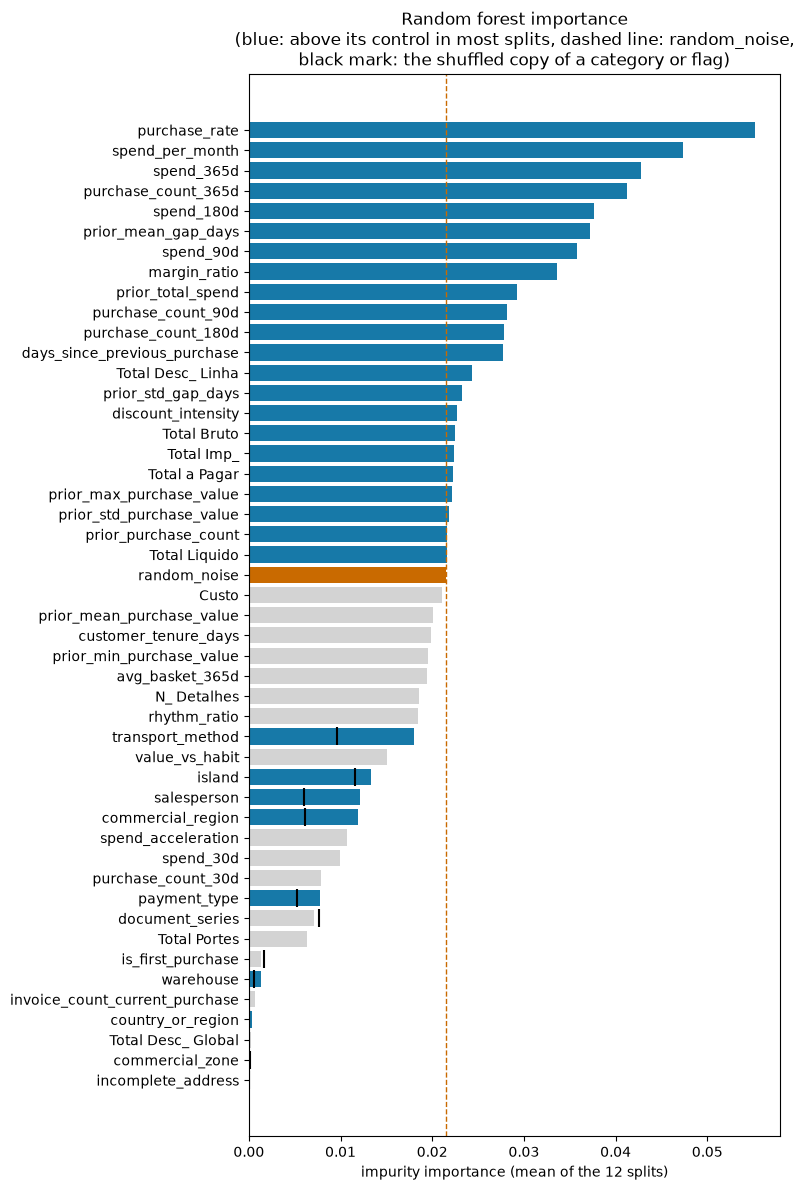

Categories and flags more important than random_noise in at least one split: []


,AP,difference,SEM,better in,verdict,variables kept,random_noise kept,stability
all candidates,0.8346,0.0,0.0,0/12,reference,48.0,12/12,1.00
random forest: above its control,0.8335,-0.0012,0.0013,5/12,inside the noise,28.0,0/12,0.71


In [20]:
def forest_importance(split):
    """Impurity importance of a random forest, added up over the columns of each variable and of each control.
    The scale of the columns does not change a tree, so the forest reads the same selection matrix."""
    forest = RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=44, n_jobs=-1)
    forest.fit(split["X_select"], split["y_train"])
    return pd.Series(forest.feature_importances_, index=split["select_variable"]).groupby(level=0).sum()


importance = pd.DataFrame({i: forest_importance(s) for i, s in enumerate(splits)})
measure("random forest: above its control",
        [{v for v in feature_cols if importance.loc[v, i] > importance.loc[control[v], i]} for i in range(len(splits))])

mean_imp = importance.mean(axis=1)
order = mean_imp[feature_cols].sort_values().index
kept_rf = pd.Series({v: sum(v in s for s in kept_by["random forest: above its control"]) for v in feature_cols})
colors = ["#C96A00" if v == "random_noise" else "#1779A8" if kept_rf[v] > 6 else "lightgrey" for v in order]
fig, ax = plt.subplots(figsize=(8, 12))
ax.barh(order, mean_imp[order], color=colors)
ax.axvline(mean_imp["random_noise"], color="#C96A00", linestyle="--", linewidth=1)
shuffled = [v for v in order if v in shuffled_vars]
ax.scatter(mean_imp[[control[v] for v in shuffled]], shuffled, marker="|", s=150, color="black", zorder=5)
ax.set_xlabel("impurity importance (mean of the 12 splits)")
ax.set_title("Random forest importance\n(blue: above its control in most splits, dashed line: random_noise,\n"
             "black mark: the shuffled copy of a category or flag)")
plt.tight_layout()
plt.show()
above_noise = [v for v in shuffled_vars if (importance.loc[v] > importance.loc["random_noise"]).any()]
print(f"Categories and flags more important than random_noise in at least one split: {above_noise}")
show(["random forest: above its control"])

The forest keeps about 28 variables, inside the noise of all the candidates. The printed line shows why the controls matter here: no category and no flag is more important than `random_noise` in any split, so with `random_noise` as the only control the forest would remove all of them. Against their shuffled copies, most categories stay (blue bars).

The forest agrees with the other methods on the strongest variables, but it reads the data in another way. It keeps the spend variables that the filter and L1 remove as copies (a forest is not hurt by redundant variables), and it drops some variables that the linear methods use, like `N_ Detalhes` and `spend_acceleration`. The forest is a second embedded method, and the classes combine one method of each family, so we use it as a check from another kind of model, not in the combination.

### **27. Combining the Methods**

Each family reads the variables in its own way, and each one has its blind spots: the filter sees each variable alone, RFE keeps the redundant variables, and L1 keeps only one variable of each group. The classes show two ways to combine them:
* a **sequence**: each method only sees the variables that the previous one kept. This was the plan of the EDA (section 8: first a redundancy filter, then the other methods). But a variable removed early can never come back.
* a **vote**: each method sees all the candidates, and a variable stays if at least 2 of the 3 methods keep it. No method can remove a variable alone.

Both use the same three methods: the filter of 24.4 (test + redundancy 0.90), RFE above its control and L1 before its control. In the sequence each variable brings its control to the next step, so RFE and L1 can still compare them.

In [21]:
members = {"filter": kept_by["filter: test + redundancy 0.90"],
           "RFE": kept_by["RFE: above its control"],
           "L1": kept_by["L1: before its control"]}

# vote: a variable stays in a split when at least 2 of the 3 methods keep it
measure("vote: 2 of 3 methods",
        [{v for v in feature_cols if sum(v in kept[i] for kept in members.values()) >= 2} for i in range(len(splits))])


def run_sequence(split, kept):
    """Filter -> RFE -> L1: each method only sees what the previous one kept, and each variable brings its control.
    Returns the variables that are still kept after each step."""
    after_rfe = above_control(rfe_ranking(split, allowed=kept | {control[v] for v in kept}), kept)
    after_l1 = before_control(lasso_path(split, allowed=after_rfe | {control[v] for v in after_rfe}), after_rfe)
    return {"filter": kept, "+ RFE": after_rfe, "+ L1": after_l1}


steps = [run_sequence(split, members["filter"][i]) for i, split in enumerate(splits)]
measure("sequence: filter -> RFE -> L1", [s["+ L1"] for s in steps])
show(["vote: 2 of 3 methods", "sequence: filter -> RFE -> L1"])

,AP,difference,SEM,better in,verdict,variables kept,random_noise kept,stability
all candidates,0.8346,0.0,0.0,0/12,reference,48.0,12/12,1.00
vote: 2 of 3 methods,0.835,0.0003,0.0009,5/12,inside the noise,27.9,0/12,0.66
sequence: filter -> RFE -> L1,0.8382,0.0035,0.0015,9/12,better,13.9,0/12,0.48


The two combinations are very different. The vote keeps about 28 variables and gives the same AP as all the candidates. The sequence keeps only about 14, half of the vote, and its AP is higher (about +0.0035), right at the limit of the noise (2 SEM). The RFE curve of section 25 already showed that the instrument works best around 10 to 15 variables. The sequence gets there without looking at the AP, because each step removes a different kind of weak variable: the filter removes the redundant and the not significant ones, then RFE and L1 remove the ones that do not beat their control.

The classes choose between the two combinations with this number (the one with the higher mean difference to all the candidates wins), and the principle of Part 2 agrees (the simpler option), so we choose the **sequence**. It is also the plan of the EDA (section 8: first a redundancy filter, then the other methods).

The price is the stability (0.48 against 0.66 for the vote): each step only sees what the previous one kept, so a small change at the start changes what comes after. The next section shows which variables change.

### **28. The Final Feature Set**

The sequence was run 12 times, once in each split, so it gave 12 lists of variables. As in the slides of the classes (RFE with cross-validation), the lists of the different folds are combined into one consensus at the end: the final set has the variables that the sequence keeps in more than half of the splits (more than 6 of 12). Lets read the sequence variable by variable (28.1) and then look at the final set (28.2).

#### **28.1. The Sequence, Variable by Variable**

In [22]:
def splits_kept(sets):
    """In how many of the 12 splits each candidate is kept."""
    return pd.Series({v: sum(v in kept for kept in sets) for v in feature_cols})


reasons = [filter_variables(assoc[i], *redund[i])[1] for i in range(len(splits))]


def why_out(i, v):
    """The step of the sequence where a variable leaves, in split i."""
    if v not in steps[i]["filter"]:
        return reasons[i][v]                     # not significant, or it repeats a stronger variable
    if v not in steps[i]["+ RFE"]:
        return "RFE: below its control"
    if v not in steps[i]["+ L1"]:
        return "L1: enters after its control"
    return ""


table = pd.DataFrame({"relevance": relevance.mean(axis=1).round(3),
                      "filter": splits_kept([s["filter"] for s in steps]),
                      "+ RFE": splits_kept([s["+ RFE"] for s in steps]),
                      "+ L1": splits_kept([s["+ L1"] for s in steps]),
                      "vote": splits_kept(kept_by["vote: 2 of 3 methods"]),
                      "random forest": splits_kept(kept_by["random forest: above its control"])})
table["decision"] = np.where(table["+ L1"] > len(splits) / 2, "kept", "out")
# for the variables that leave: the most common reason, over the splits where they leave
table["main reason when it leaves"] = [
    pd.Series([why_out(i, v) for i in range(len(splits)) if why_out(i, v)]).mode().iloc[0] if table.loc[v, "+ L1"] < len(splits) else ""
    for v in table.index]
table = table.sort_values(["decision", "+ L1", "relevance"], ascending=[True, False, False])
table

,relevance,filter,+ RFE,+ L1,vote,random forest,decision,main reason when it leaves
purchase_count_90d,0.381,12,12,12,12,11,kept,
prior_std_gap_days,0.278,12,12,12,12,8,kept,
purchase_count_365d,0.386,11,11,11,12,12,kept,repeats purchase_count_180d
transport_method,0.285,12,12,11,12,12,kept,L1: enters after its control
margin_ratio,0.118,12,12,11,12,12,kept,L1: enters after its control
salesperson,0.164,11,11,10,12,12,kept,L1: enters after its control
purchase_rate,0.391,12,11,9,12,12,kept,L1: enters after its control
prior_max_purchase_value,0.245,11,9,9,12,7,kept,RFE: below its control
is_first_purchase,0.152,12,10,9,12,2,kept,RFE: below its control
Total Bruto,0.073,10,10,8,10,9,kept,L1: enters after its control


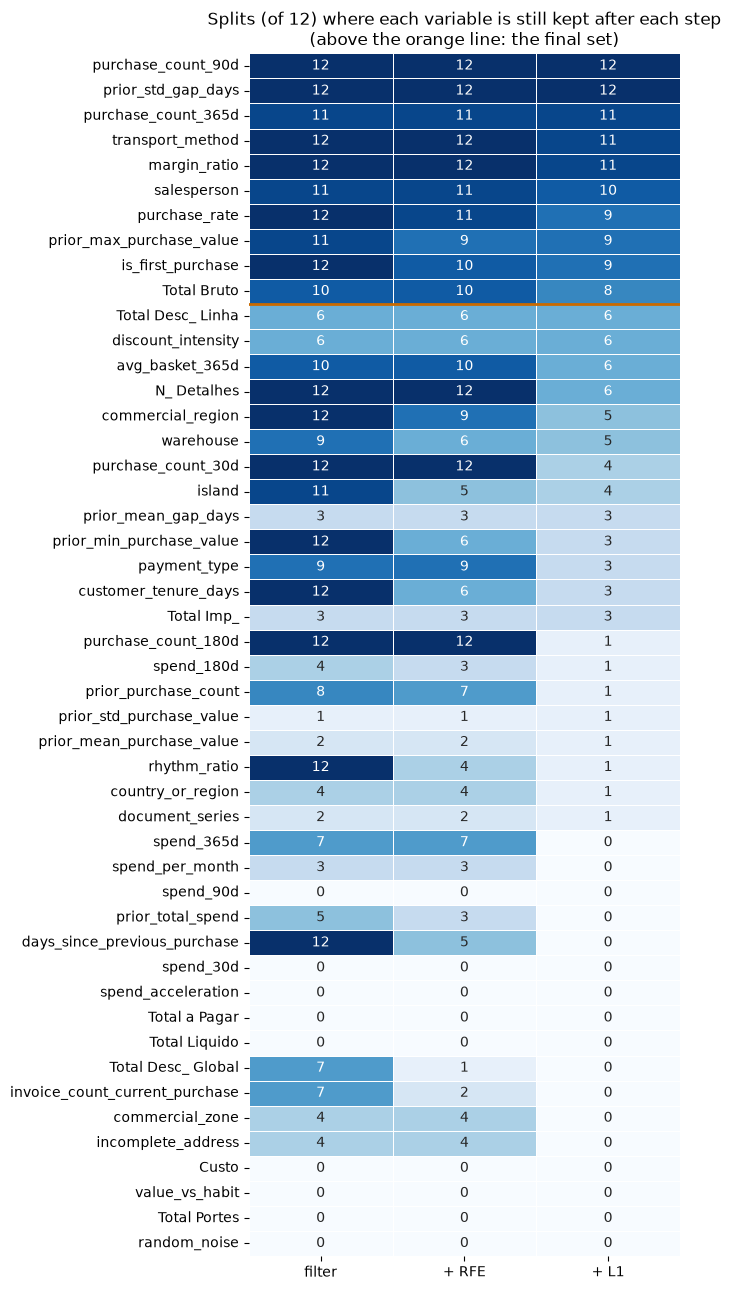

In [23]:
fig, ax = plt.subplots(figsize=(7, 13))
sns.heatmap(table[["filter", "+ RFE", "+ L1"]], annot=True, fmt="d", cmap="Blues", vmin=0, vmax=12,
            cbar=False, linewidths=0.5, ax=ax)
ax.axhline((table["decision"] == "kept").sum(), color="#C96A00", linewidth=2)
ax.set_title("Splits (of 12) where each variable is still kept after each step\n(above the orange line: the final set)")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

Reading the table from the top:
* **The core**: frequency (`purchase_count_90d`, `purchase_count_365d`, `purchase_rate`), regularity (`prior_std_gap_days`), value (`prior_max_purchase_value`, `Total Bruto`, `margin_ratio`), the first purchases (`is_first_purchase`) and two categories (`transport_method` and `salesperson`). They are kept in most splits, and the vote and the forest also keep most of them.
* **Recency** is in the core through `purchase_count_90d`: no purchase in the last 90 days means that the previous one is older than 90 days (section 8). So for the linear model `days_since_previous_purchase` adds little once the counts are in, and RFE and L1 remove it, although the vote keeps it in every split.
* **The copies**: many variables leave because they repeat a stronger one (the reason column). From each group one variable stays: `Total Bruto` for the invoice totals, the counts for the spend windows, `purchase_rate` for `prior_mean_gap_days`.
* **The edge**: a few variables are kept in about half of the splits, just below the majority. `Total Desc_ Linha` and `discount_intensity` are an example: they are copies (24.3), and the filter keeps the one that is more relevant in each split, so each one is kept in about half of the splits and never together. The discounts are in every split, but neither copy reaches the majority.
* **The categories**: `transport_method` and `salesperson` beat their shuffled copies in most splits, so their signal is not luck, and after the grouping of section 17 they are not identifiers (23). The other categories do not stay: the geography of `clientes.csv` (`commercial_region`, `island`, `country_or_region`), `payment_type`, `warehouse`, `commercial_zone` and `document_series` are not significant in the filter or do not beat their copies often enough.
* `random_noise` leaves at the first step in every split (not significant).

#### **28.2. The Final Set**

In [24]:
selected = [v for v in feature_cols if table.loc[v, "decision"] == "kept"]
selected_columns = {group: [c for c in cols if c in selected] for group, cols in final_columns.items()}
sequence_sets = [s["+ L1"] for s in steps]   # the selection of each split, for the comparisons of Part 4
for group, cols in selected_columns.items():
    print(f"{group} ({len(cols)} of {len(final_columns[group])}): {', '.join(cols)}")
print(f"\nSelected: {len(selected)} of {len(feature_cols)} variables | random_noise in the set: {'random_noise' in selected}")
width = {name: make_preprocessor(**columns, **final_recipe).fit_transform(dev[feature_cols]).shape[1]
         for name, columns in [("final set", selected_columns), ("all candidates", final_columns)]}
print(f"Columns after Layer B, fitted on the development rows | final set: {width['final set']} | all candidates: {width['all candidates']}")

log_cols (6 of 32): Total Bruto, prior_max_purchase_value, prior_std_gap_days, purchase_count_90d, purchase_count_365d, purchase_rate
plain_cols (1 of 5): margin_ratio
cat_cols (2 of 9): salesperson, transport_method
flag_cols (1 of 2): is_first_purchase

Selected: 10 of 48 variables | random_noise in the set: False
Columns after Layer B, fitted on the development rows | final set: 54 | all candidates: 136


The final set has 10 of the 48 candidates: 7 numeric variables, the flag `is_first_purchase` and 2 categories, without `random_noise` and without identifiers. After Layer B they are 54 columns instead of 136. The final set is smaller than the selections of each split (about 14, section 27), because the variables that change from split to split stay below the majority: only the core that the sequence keeps most of the time stays.

In [25]:
# the same sequence fitted once on all the development rows (the biggest train set we have)
dev_idx = df_model.index[is_dev]
prep = make_preprocessor(**final_columns, **final_recipe)
X_dev = prep.fit_transform(df_model.loc[dev_idx, feature_cols])
names = encoded_names(prep)
X_select, select_variable = selection_matrix(X_dev, variable_of(names), rng)
dev_split = {"train_idx": dev_idx, "names": names, "variable": variable_of(names), "X_train": X_dev,
             "y_train": df_model.loc[dev_idx, target_col].to_numpy(), "X_select": X_select, "select_variable": select_variable}

dev_set = run_sequence(dev_split, filter_variables(association(dev_split), *redundancy(dev_split))[0])["+ L1"]
print(f"Sequence fitted on all the development rows: {len(dev_set)} variables | in common with the final set: {len(dev_set & set(selected))}")
print(f"Only in the final set: {sorted(set(selected) - dev_set)}")
print(f"Only in the sequence on all the development rows: {sorted(dev_set - set(selected))}")

Sequence fitted on all the development rows: 15 variables | in common with the final set: 9
Only in the final set: ['Total Bruto']
Only in the sequence on all the development rows: ['Total Desc_ Linha', 'Total Imp_', 'commercial_region', 'country_or_region', 'incomplete_address', 'warehouse']


The sequence fitted once on all the development rows keeps 15 variables, with 9 of the 10 of the final set (it keeps `Total Imp_` instead of `Total Bruto`, a variable that the filter usually removes as a copy of `Total Bruto`). The other extra variables are the edge of 28.1 or weaker: `Total Desc_ Linha`, `commercial_region` and `warehouse` are kept in about half of the splits, and `country_or_region` and `incomplete_address` almost never. In one fit, one draw of the shuffled copies decides these cases, so they come and go.

This is the reason of the slides for combining the lists of the folds: one fit gives one list, while 12 fits show which variables are kept every time. So the final set is the core that the strategy keeps in most splits.

#### **28.3. Summary of the Decisions**

| Section | Decision | Options tested | Choice | Why |
|---|---|---|---|---|
| 22 | How to select | – | every method inside each split; a variable stays only if it beats a control | no leakage; no cut is chosen with the AP |
| 22.1 | Controls | `random_noise` for every variable, a control of the same shape | `random_noise` for the numeric variables, a shuffled copy for the categories and flags | shuffled categories beat `random_noise` in almost every split (25) |
| 23 | Identifiers | `ID` and `customer_id` (as a number and as a category) | out | no gain; as a category `customer_id` loses AP |
| 24.1 | Constant columns | `VarianceThreshold(0)` | nothing to remove | no constant column |
| 24.4 | Filter | test, + redundancy 0.90 or 0.70, 10 most relevant | test + redundancy 0.90 | inside the noise; best on average; the limit of the EDA |
| 25 | RFE | k strongest (curve), above its control | above its control | the best k is too optimistic |
| 26.1 | L1 | C from 0.001 to 1, C = 0.1 of the classes | before its control | C = 0.1 keeps `random_noise` in 10 of 12 splits |
| 26.2 | Random forest | above its control | only a check | second embedded method, another kind of model |
| 27 | Combination | vote 2 of 3, sequence | sequence: filter → RFE → L1 | higher AP with half the variables; the plan of the EDA |
| 28 | Final set | majority of the 12 splits, one fit on all the development rows | kept by the sequence in more than 6 of 12 splits | the core that the strategy keeps every time |

As in Part 2, the instrument is robust: every selection is inside the noise of all the candidates, or at its limit. So the value of Part 3 is not a higher AP. It is a model with 10 variables instead of 48, where every variable beat a control of its own shape, without identifiers and without noise.

Part 4 receives:
* `selected_columns`: the final set, in the same groups as `final_columns`, so the pipeline is `make_preprocessor(**selected_columns, **final_recipe)`.
* `sequence_sets`: the selection of each of the 12 splits. The final set was chosen with all the development rows, so it already saw the validation blocks of the earlier splits, and its AP on these splits would be a bit optimistic. As the classes say, we carry the strategy and not only the columns: in the comparisons of Part 4 on the same 12 splits, each split can use its own selection. The holdout (2024 and 2025) was never used, so it stays a clean check of the final set.
* The selection was measured with a linear model. The forest (26.2) keeps some variables that the sequence removes, like the spend variables, so in Part 4 the tree models should also be compared with all the candidates, to check that they do not lose with the final set.